In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
PROJECT_ROOT = Path.cwd().parent

TRAIN_DIR = PROJECT_ROOT / "data" / "train"
TEST_DIR = PROJECT_ROOT / "data" / "test"

print("Train directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)

print("Train exists:", TRAIN_DIR.exists())
print("Test exists:", TEST_DIR.exists())

Train directory: c:\Users\Animesh\OneDrive\Desktop\EmotionRecognition\data\train
Test directory: c:\Users\Animesh\OneDrive\Desktop\EmotionRecognition\data\test
Train exists: True
Test exists: True


In [8]:
emotions = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

train_counts = {}
test_counts = {}

for emotion in emotions:
    train_counts[emotion] = len(
        list((TRAIN_DIR / emotion).glob("*"))
    )

    test_counts[emotion] = len(
        list((TEST_DIR / emotion).glob("*"))
    )

df = pd.DataFrame({
    "Emotion": emotions,
    "Train Images": [train_counts[e] for e in emotions],
    "Test Images": [test_counts[e] for e in emotions]
})

display(df)

print("Total training images:", sum(train_counts.values()))
print("Total testing images:", sum(test_counts.values()))

,Emotion,Train Images,Test Images
0,angry,3995,958
1,disgust,436,111
2,fear,4097,1024
3,happy,7215,1774
4,neutral,4965,1233
5,sad,4830,1247
6,surprise,3171,831


Total training images: 28709
Total testing images: 7178


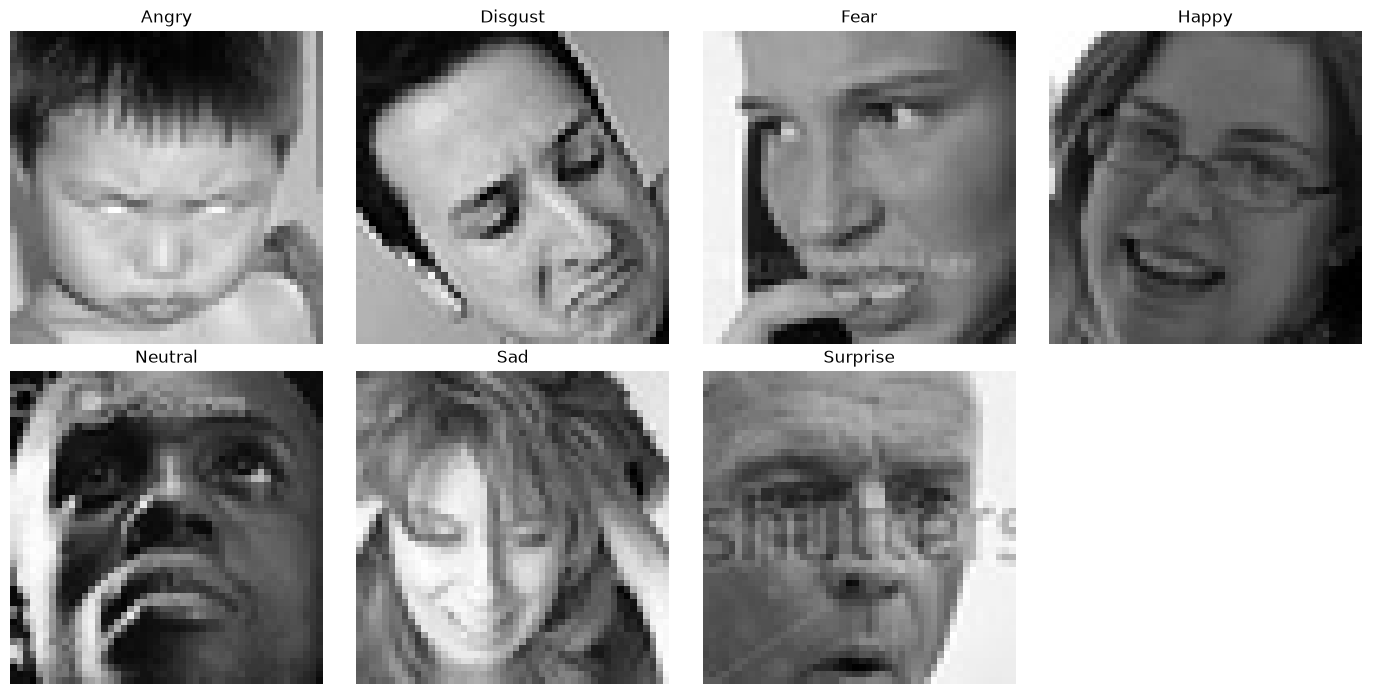

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, emotion in zip(axes.flat, emotions):
    image_files = list((TRAIN_DIR / emotion).glob("*"))

    if image_files:
        image = Image.open(image_files[0])

        ax.imshow(image, cmap="gray")
        ax.set_title(emotion.capitalize())
        ax.axis("off")

for ax in axes.flat[len(emotions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
for emotion in emotions:
    image_files = list((TRAIN_DIR / emotion).glob("*"))

    if image_files:
        image = Image.open(image_files[0])

        print(
            emotion,
            "Size:", image.size,
            "Mode:", image.mode
        )

angry Size: (48, 48) Mode: L
disgust Size: (48, 48) Mode: L
fear Size: (48, 48) Mode: L
happy Size: (48, 48) Mode: L
neutral Size: (48, 48) Mode: L
sad Size: (48, 48) Mode: L
surprise Size: (48, 48) Mode: L


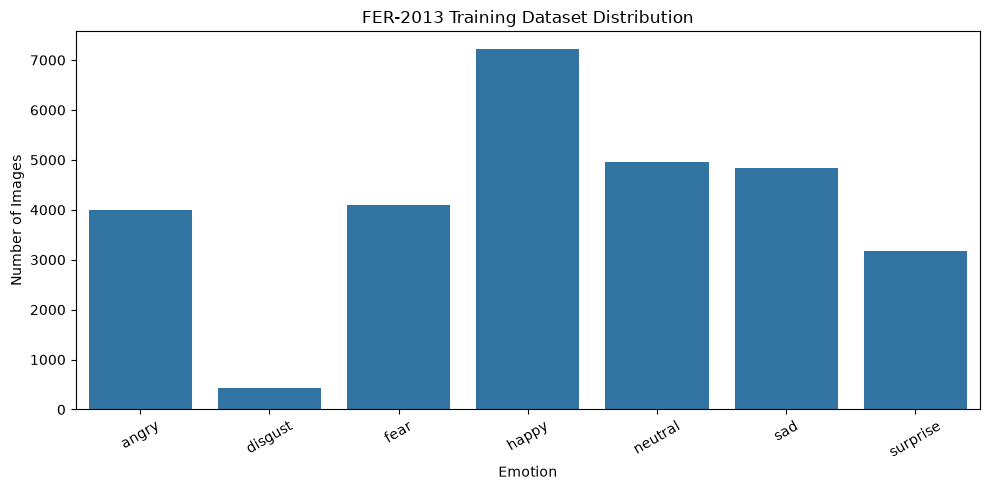

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Emotion",
    y="Train Images"
)

plt.title("FER-2013 Training Dataset Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()